# Startup Screening Model: Perceptual Robotics

This notebook supports the investment memo on **Perceptual Robotics**, a Bristol and Athens company that builds autonomous drones and AI software for wind turbine blade inspection.

It does three things:

1. Trains two simple classifiers on a public dataset of 923 US startups to estimate how likely a startup is to end in an acquisition rather than a shutdown.
2. Checks how well those models work and what drives them.
3. Scores Perceptual Robotics under several input scenarios and explains how far the result can be trusted.

**Read this first.** The model is a screening aid, not a prediction of returns. It was trained on US companies, its label only separates *acquired* from *closed*, and it cannot see revenue, team quality, or market size.

## 1. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Load the data

The file `startup_data.csv` holds one row per US startup, with funding history, investor flags, sector and the final outcome.

In [2]:
df = pd.read_csv("startup_data.csv")
print(df.shape)
df["status"].value_counts()

(923, 49)


status
acquired    597
closed      326
Name: count, dtype: int64

## 3. Define the target

The dataset contains only two outcomes: **acquired** and **closed**. I label acquired as 1 and closed as 0. This means "success" here means "was acquired", which is a narrower idea than a venture-scale outcome: many acquisitions are small, and a company that stays independent and thrives would not appear at all.

In [3]:
df["success"] = (df["status"] == "acquired").astype(int)
df["success"].value_counts().rename({1: "acquired (1)", 0: "closed (0)"})

success
acquired (1)    597
closed (0)      326
Name: count, dtype: int64

## 4. Choose and clean the features

Features were chosen so that each one can be filled in for a company today:

| Feature | Meaning |
|---|---|
| `funding_rounds` | number of funding rounds |
| `log_funding` | log of total funding in USD, to reduce skew |
| `age_at_last_funding` | years from founding to the latest round |
| `has_VC`, `has_angel` | venture and angel investors present |
| `category` | sector, with rare sectors grouped as `other` |

Two features from the raw file are left out on purpose:

- **Location.** Every company is American, so the model has no valid way to score a UK or Greek company.
- **`is_top500`.** It is unclear how this flag is defined, and an investor cannot reliably fill it in for a new company.

Some ages are negative (funding dated before founding), which is a data error. I set those to zero.

In [4]:
data = df[[
    "success", "funding_rounds", "funding_total_usd", "age_last_funding_year",
    "has_VC", "has_angel", "category_code",
]].copy()

print("Missing values per column:")
print(data.isna().sum().to_string())
print("\nNegative ages set to zero:", int((data["age_last_funding_year"] < 0).sum()))

data["age_at_last_funding"] = data["age_last_funding_year"].clip(lower=0)
data["log_funding"] = np.log1p(data["funding_total_usd"])

# group sectors with fewer than 20 companies into "other"
sector_counts = data["category_code"].value_counts()
common = sector_counts[sector_counts >= 20].index
data["category"] = data["category_code"].where(data["category_code"].isin(common), "other")

NUM_COLS = ["funding_rounds", "log_funding", "age_at_last_funding"]
BIN_COLS = ["has_VC", "has_angel"]
CAT_COLS = ["category"]
FEATURES = NUM_COLS + BIN_COLS + CAT_COLS

X = data[FEATURES]
y = data["success"]
print("\nSectors used:", sorted(data["category"].unique()))

Missing values per column:
success                  0
funding_rounds           0
funding_total_usd        0
age_last_funding_year    0
has_VC                   0
has_angel                0
category_code            0

Negative ages set to zero: 13

Sectors used: ['advertising', 'biotech', 'cleantech', 'ecommerce', 'enterprise', 'games_video', 'hardware', 'mobile', 'network_hosting', 'other', 'public_relations', 'semiconductor', 'software', 'web']


## 5. Explore

In [5]:
summary = data.groupby("success")[["funding_rounds", "funding_total_usd", "age_at_last_funding"]].mean()
summary.index = ["closed", "acquired"]
summary.round(2)

,funding_rounds,funding_total_usd,age_at_last_funding
closed,1.92,15115322.46,3.68
acquired,2.52,31046621.93,4.09


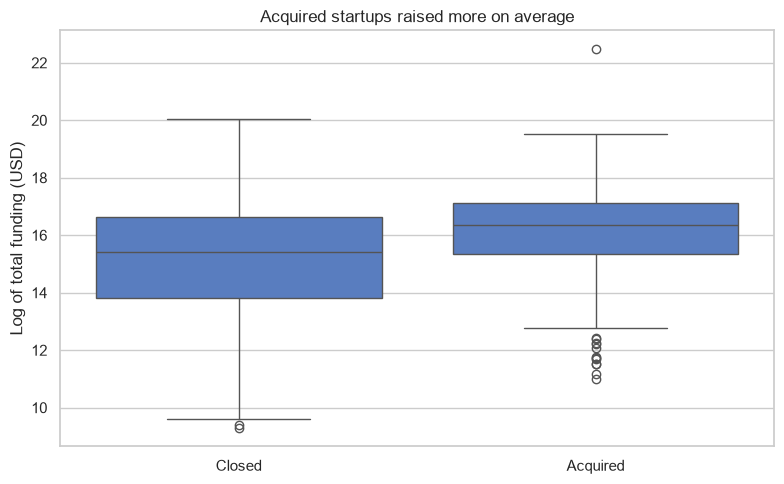

In [6]:
fig, ax = plt.subplots()
sns.boxplot(x="success", y="log_funding", data=data, ax=ax)
ax.set_xticks([0, 1], ["Closed", "Acquired"])
ax.set_xlabel("")
ax.set_ylabel("Log of total funding (USD)")
ax.set_title("Acquired startups raised more on average")
plt.tight_layout()
plt.show()

## 6. Train and compare two models

Logistic regression is the simple baseline and is easy to explain. Random forest can capture interactions. Both use the same features. I hold out 30% of companies as a test set and also run 5-fold cross-validation, because a single split on 923 rows is noisy.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

prep = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("bin", "passthrough", BIN_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
])

models = {
    "Logistic regression": Pipeline([
        ("prep", prep),
        ("clf", LogisticRegression(max_iter=1000)),
    ]),
    "Random forest": Pipeline([
        ("prep", prep),
        ("clf", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE
        )),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    cv_acc = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    cv_auc = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "model": name,
        "cv_accuracy": cv_acc.mean(),
        "cv_auc": cv_auc.mean(),
        "test_accuracy": accuracy_score(y_test, pred),
        "test_auc": roc_auc_score(y_test, proba),
    })

baseline = y.mean()
results = pd.DataFrame(rows).set_index("model").round(3)
print(f"Share of acquired startups (accuracy of always guessing 'acquired'): {baseline:.3f}")
results

Share of acquired startups (accuracy of always guessing 'acquired'): 0.647


,cv_accuracy,cv_auc,test_accuracy,test_auc
model,,,,
Logistic regression,0.713,0.702,0.668,0.674
Random forest,0.688,0.702,0.668,0.704


In [8]:
for name, model in models.items():
    print(name)
    print(classification_report(y_test, model.predict(X_test), target_names=["closed", "acquired"]))

Logistic regression
              precision    recall  f1-score   support

      closed       0.55      0.32      0.40        98
    acquired       0.70      0.86      0.77       179

    accuracy                           0.67       277
   macro avg       0.63      0.59      0.59       277
weighted avg       0.65      0.67      0.64       277

Random forest
              precision    recall  f1-score   support

      closed       0.56      0.30      0.39        98
    acquired       0.69      0.87      0.77       179

    accuracy                           0.67       277
   macro avg       0.63      0.58      0.58       277
weighted avg       0.65      0.67      0.64       277



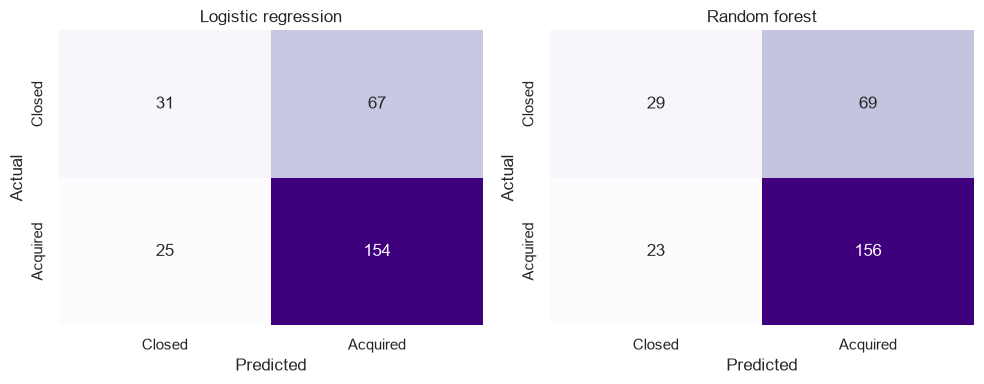

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", cbar=False, ax=ax,
                xticklabels=["Closed", "Acquired"], yticklabels=["Closed", "Acquired"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=200)
plt.show()

**How to read this.** Compare the accuracy to the baseline above: a model that always says "acquired" is already right about two times in three. The model adds some signal, but not much, and it finds closed startups less reliably than acquired ones.

## 7. What drives the model

Permutation importance measures how much accuracy drops when one feature is shuffled. It is computed on the held-out test set for the random forest.

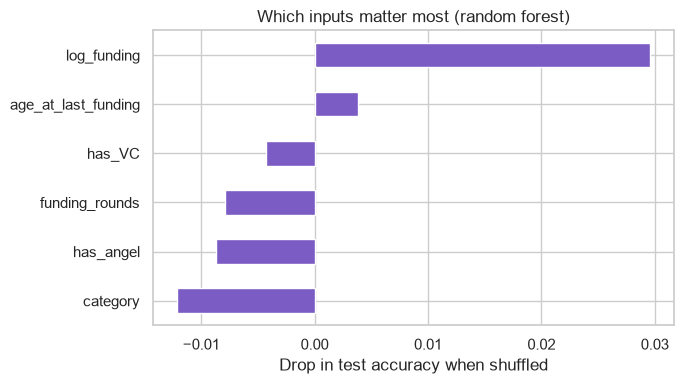

log_funding            0.0296
age_at_last_funding    0.0039
has_VC                -0.0043
funding_rounds        -0.0079
has_angel             -0.0087
category              -0.0122
dtype: float64

In [10]:
rf = models["Random forest"]
imp = permutation_importance(
    rf, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="accuracy"
)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
importance.plot(kind="barh", ax=ax, color="#7a5cc4")
ax.set_xlabel("Drop in test accuracy when shuffled")
ax.set_title("Which inputs matter most (random forest)")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance.png", dpi=200)
plt.show()
importance.sort_values(ascending=False).round(4)

## 8. Final models and scoring function

For scoring a new company, both models are refit on all 923 companies.

In [11]:
final_models = {}
for name, model in models.items():
    final_models[name] = clone(model).fit(X, y)

def score(inputs: dict) -> dict:
    row = pd.DataFrame([inputs])[FEATURES]
    return {name: float(m.predict_proba(row)[0, 1]) for name, m in final_models.items()}

## 9. Perceptual Robotics: inputs

Inputs come from the investment memo. Where a number is not disclosed, I use a base case and test alternatives.

| Input | Base case | Why |
|---|---|---|
| Funding rounds | 4 | 2019 (EUR 0.6M), 2021 (GBP 1.6M), 2023 (investment by Brookstreet, amount undisclosed), 2026 (more than GBP 4M) |
| Total funding | USD 8M | About USD 0.65M + 2.2M + 5.3M from the disclosed rounds; CB Insights lists USD 6.8M |
| Age at last funding | 10 years | Founded 2016, latest round 2026 |
| Venture investors | yes | Metavallon VC, TSP Ventures, Loggerhead Ventures |
| Angel investors | yes | The 2021 round included strategic angel investors |
| Sector | hardware | Closest single label for drones plus AI; cleantech and other are tested too |

Figures are approximate and converted from pounds and euros at rough rates.

In [12]:
BASE = {
    "funding_rounds": 4,
    "log_funding": float(np.log1p(8_000_000)),
    "age_at_last_funding": 10.0,
    "has_VC": 1,
    "has_angel": 1,
    "category": "hardware",
}

def variant(label, **changes):
    inputs = {**BASE, **changes}
    if "funding_usd" in changes:
        inputs["log_funding"] = float(np.log1p(inputs.pop("funding_usd")))
    return label, inputs

scenarios = [
    variant("Base case"),
    variant("Sector: cleantech", category="cleantech"),
    variant("Sector: other", category="other"),
    variant("Funding USD 6.8M", funding_usd=6_800_000),
    variant("Funding USD 15M", funding_usd=15_000_000),
    variant("3 funding rounds", funding_rounds=3),
    variant("5 funding rounds", funding_rounds=5),
    variant("No angel investors", has_angel=0),
]

scores = pd.DataFrame(
    [{"scenario": label, **score(inputs)} for label, inputs in scenarios]
).set_index("scenario")
scores["average"] = scores.mean(axis=1)
scores.round(3)

,Logistic regression,Random forest,average
scenario,,,
Base case,0.378,0.595,0.486
Sector: cleantech,0.351,0.645,0.498
Sector: other,0.679,0.697,0.688
Funding USD 6.8M,0.359,0.605,0.482
Funding USD 15M,0.454,0.612,0.533
3 funding rounds,0.338,0.595,0.467
5 funding rounds,0.420,0.592,0.506
No angel investors,0.289,0.551,0.420


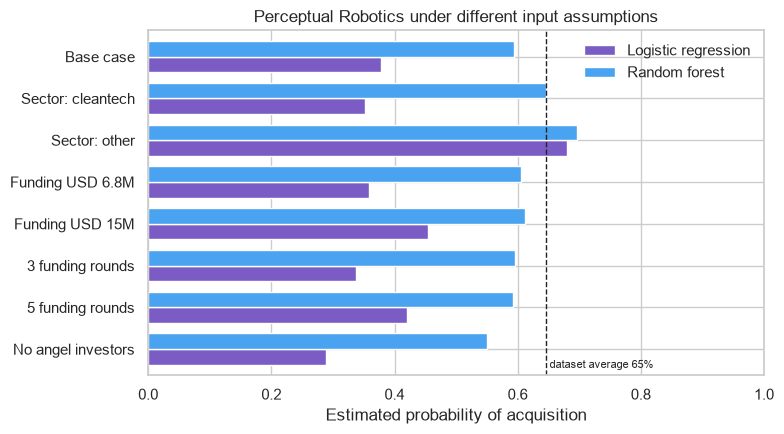

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = scores[["Logistic regression", "Random forest"]].iloc[::-1]
plot_df.plot(kind="barh", ax=ax, color=["#7a5cc4", "#4aa3f0"], width=0.75)
ax.axvline(baseline, color="#222222", linestyle="--", linewidth=1)
ax.text(baseline + 0.005, -0.45, f"dataset average {baseline:.0%}", fontsize=8)
ax.set_xlim(0, 1)
ax.set_xlabel("Estimated probability of acquisition")
ax.set_ylabel("")
ax.set_title("Perceptual Robotics under different input assumptions")
ax.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "perceptual_scores.png", dpi=200)
plt.show()

## 10. Reading the result

Run the next cell for a plain summary. Then keep these limits in mind when you use the number in the memo.

In [14]:
lo, hi = scores["average"].min(), scores["average"].max()
base_avg = scores.loc["Base case", "average"]
print(f"Base case, average of both models: {base_avg:.0%}")
print(f"Range across scenarios: {lo:.0%} to {hi:.0%}")
print(f"Dataset average for comparison: {baseline:.0%}")
print()
top_driver = importance.sort_values(ascending=False).index[0]
print(f"Most important input in the random forest: {top_driver}")

export = {
    "baseline_acquired_share": float(baseline),
    "results": results.reset_index().to_dict(orient="records"),
    "scores": scores.round(4).reset_index().to_dict(orient="records"),
    "importance": importance.sort_values(ascending=False).round(4).to_dict(),
    "n_companies": int(len(data)),
}
Path("model_results.json").write_text(json.dumps(export, indent=2))

Base case, average of both models: 49%
Range across scenarios: 42% to 69%
Dataset average for comparison: 65%

Most important input in the random forest: log_funding


1738

### Limits

- **US-only training data.** Every company is American. Perceptual Robotics is British with a Greek subsidiary, so its score is an extrapolation.
- **Narrow label.** The model separates acquired from closed. It says nothing about companies that stay independent, and nothing about the size of an exit.
- **Hindsight in the features.** Funding totals and round counts are measured at the end of each company's life, so successful companies had more time to raise. This inflates the link between funding and success.
- **Survivorship and selection.** The file only contains startups that raised money and whose outcome is known.
- **Missing signals.** Revenue, customers, team quality, market size and competition are not in the data, and those are the questions the memo is about.
- **Hardware and energy are thin.** The dataset has few comparable companies, so the sector effect is noisy.

Use the score as one input next to the memo's diligence work, not as a reason to invest or pass.